# BÀI THỰC HÀNH SỐ 2 - BÀI 2 (Trang 15–23)
## Phân lớp dữ liệu Adult Income (`adult.data.csv` & `adult.test.csv`)

- **Họ tên sinh viên:** `Nguyễn Phạm Bảo Khanh`
- **MSSV:** `6451071033`
- **Môn học:** Khai phá dữ liệu (Data Mining)
- **Mục tiêu:** Nhập và tiền xử lý tập dữ liệu Adult Income, khảo sát tương quan Pearson, chuyển đổi one-hot vector, xây dựng và so sánh hiệu năng ba mô hình phân lớp **ID3**, **CART** và **Naïve Bayes (GaussianNB)** trong dự đoán thu nhập (`<=50K` / `>50K`).

## Thiết lập môi trường và cấu hình dữ liệu

In [1]:
%matplotlib inline
import os
import sys
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

STUDENT_NAME = "Nguyễn Phạm Bảo Khanh"
MSSV = "6451071033"
DATASET_DRIVE_URL = "https://drive.google.com/drive/folders/1KK--zL3h4hWrfIl--FIcrww3dLx-epiB?usp=sharing"

def get_dataset_path(filename: str) -> str:
    """Tìm đường dẫn tập dữ liệu cục bộ, trên Google Drive (Colab), hoặc tải bằng gdown."""
    local_path = os.path.join("Dataset", filename)
    if os.path.exists(local_path):
        return local_path

    if "google.colab" in sys.modules:
        from google.colab import drive
        if not os.path.exists("/content/drive/MyDrive"):
            drive.mount("/content/drive")
        colab_path = os.path.join("/content/drive/MyDrive/Dataset", filename)
        if os.path.exists(colab_path):
            return colab_path

    os.makedirs("Dataset", exist_ok=True)
    subprocess.run(
        [sys.executable, "-m", "gdown", "--folder", DATASET_DRIVE_URL, "-O", "Dataset"],
        check=True,
    )
    if not os.path.exists(local_path):
        raise FileNotFoundError(f"Không tìm thấy tệp dữ liệu tại {local_path}")
    return local_path

print(f"{STUDENT_NAME} - {MSSV}")
train_path = get_dataset_path("adult.data.csv")
test_path = get_dataset_path("adult.test.csv")
print(f"Đường dẫn tập huấn luyện: {train_path}")
print(f"Đường dẫn tập kiểm thử:   {test_path}")

Nguyễn Phạm Bảo Khanh - 6451071033
Đường dẫn tập huấn luyện: Dataset\adult.data.csv
Đường dẫn tập kiểm thử:   Dataset\adult.test.csv


## Câu 1: Nhập dữ liệu đầu vào và thống kê số lượng dữ liệu ban đầu

In [2]:
print(f"{STUDENT_NAME} - {MSSV}")

# Đọc dữ liệu với skipinitialspace=True và loại bỏ khoảng trắng thừa ở các cột chuỗi
train_raw = pd.read_csv(train_path, skipinitialspace=True)
test_raw = pd.read_csv(test_path, skipinitialspace=True)

for df in (train_raw, test_raw):
    for col in df.select_dtypes(exclude=[np.number]).columns:
        df[col] = df[col].str.strip()

print(f"Số lượng dữ liệu huấn luyện ban đầu (adult.data.csv): {len(train_raw)} dòng, {train_raw.shape[1]} cột")
print(f"Số lượng dữ liệu kiểm thử ban đầu (adult.test.csv):   {len(test_raw)} dòng, {test_raw.shape[1]} cột")

print("\n--- 5 dòng đầu tập huấn luyện (train_raw.head()) ---")
display(train_raw.head())

print("\n--- 5 dòng đầu tập kiểm thử (test_raw.head()) ---")
display(test_raw.head())

print("\n--- Thông tin cấu trúc tập huấn luyện (train_raw.info()) ---")
train_raw.info()

print("\n--- Thông tin cấu trúc tập kiểm thử (test_raw.info()) ---")
test_raw.info()

Nguyễn Phạm Bảo Khanh - 6451071033
Số lượng dữ liệu huấn luyện ban đầu (adult.data.csv): 32561 dòng, 15 cột
Số lượng dữ liệu kiểm thử ban đầu (adult.test.csv):   16281 dòng, 14 cột

--- 5 dòng đầu tập huấn luyện (train_raw.head()) ---


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



--- 5 dòng đầu tập kiểm thử (test_raw.head()) ---


,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K



--- Thông tin cấu trúc tập huấn luyện (train_raw.info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education-num   32561 non-null  int64
 5   marital-status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital-gain    32561 non-null  int64
 11  capital-loss    32561 non-null  int64
 12  hours-per-week  32561 non-null  int64
 13  native-country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 6.2 MB

--- Thông tin cấu trúc tập kiểm thử (test_raw.info()) ---
<cla

**Nhận xét Câu 1:**
- Tập huấn luyện (`adult.data.csv`) gồm **32.561** dòng và **15** cột (có cột `fnlwgt`).
- Tập kiểm thử (`adult.test.csv`) gồm **16.281** dòng và **14** cột (không có cột `fnlwgt`).
- Các cột chuỗi trong cả hai tệp có khoảng trắng ở đầu giá trị trong CSV gốc nên đã được xử lý sạch bằng `skipinitialspace=True` và `.str.strip()`.

## Câu 2: Tiền xử lý dữ liệu
- Xóa những dòng chứa giá trị trống được ký hiệu bằng dấu `'?'`.
- Xóa cột `fnlwgt` trong dữ liệu huấn luyện vì cột này không có trong dữ liệu kiểm thử.
- Nối dữ liệu huấn luyện và kiểm thử thành một bảng thống nhất `data`.

In [3]:
print(f"{STUDENT_NAME} - {MSSV}")

train_q_rows = train_raw.isin(['?']).any(axis=1).sum()
test_q_rows = test_raw.isin(['?']).any(axis=1).sum()
print(f"Số dòng chứa '?' trong tập huấn luyện: {train_q_rows}")
print(f"Số dòng chứa '?' trong tập kiểm thử:   {test_q_rows}")

# Xóa các dòng chứa '?'
train_clean = train_raw[~train_raw.isin(['?']).any(axis=1)].copy()
test_clean = test_raw[~test_raw.isin(['?']).any(axis=1)].copy()

# Xóa cột 'fnlwgt' trong tập huấn luyện
if 'fnlwgt' in train_clean.columns:
    train_clean = train_clean.drop(columns=['fnlwgt'])

# Nối dữ liệu huấn luyện và kiểm thử
data = pd.concat([train_clean, test_clean], ignore_index=True)

n_train = len(train_clean)
n_test = len(test_clean)
print(f"\nNumber of training data: {n_train}")
print(f"Number of test data: {n_test}")

print("\n--- Thông tin khối dữ liệu sau khi nối (data.info()) ---")
data.info()

print("\n--- 5 dòng đầu tiên của data ---")
display(data.head())

Nguyễn Phạm Bảo Khanh - 6451071033
Số dòng chứa '?' trong tập huấn luyện: 2399
Số dòng chứa '?' trong tập kiểm thử:   1221

Number of training data: 30162
Number of test data: 15060

--- Thông tin khối dữ liệu sau khi nối (data.info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 45222 entries, 0 to 45221
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             45222 non-null  int64
 1   workclass       45222 non-null  str  
 2   education       45222 non-null  str  
 3   education-num   45222 non-null  int64
 4   marital-status  45222 non-null  str  
 5   occupation      45222 non-null  str  
 6   relationship    45222 non-null  str  
 7   race            45222 non-null  str  
 8   sex             45222 non-null  str  
 9   capital-gain    45222 non-null  int64
 10  capital-loss    45222 non-null  int64
 11  hours-per-week  45222 non-null  int64
 12  native-country  45222 non-null  str  
 13  income      

,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


**Nhận xét Câu 2:**
- Sau khi loại bỏ **2.399** dòng chứa `'?'` ở tập huấn luyện và **1.221** dòng chứa `'?'` ở tập kiểm thử, cùng với việc bỏ cột `fnlwgt`, thu được **30.162** mẫu huấn luyện và **15.060** mẫu kiểm thử.
- Khối dữ liệu hợp nhất `data` có **45.222** dòng và **14** cột, không còn giá trị thiếu (`45222 non-null` trên tất cả các cột).

## Câu 3: Khảo sát độ tương đồng giữa các thuộc tính bằng công thức Pearson

Nguyễn Phạm Bảo Khanh - 6451071033
Hệ số tương quan Pearson tuyệt đối lớn nhất (ngoài đường chéo chính): 0.1462


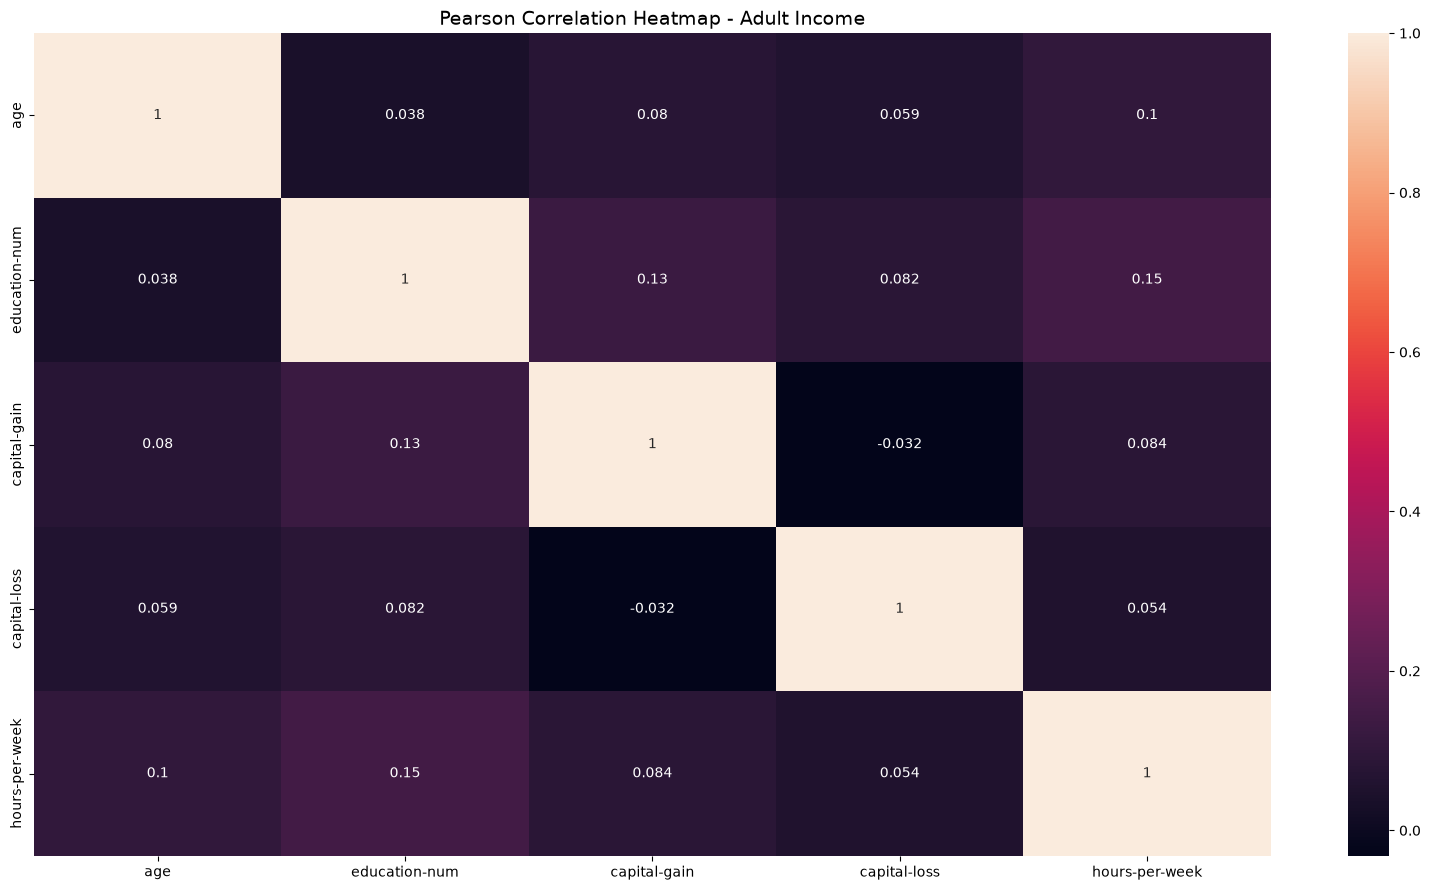

In [4]:
print(f"{STUDENT_NAME} - {MSSV}")

corr_matrix = data.corr(method='pearson', numeric_only=True)
off_diag = corr_matrix.where(~np.eye(len(corr_matrix), dtype=bool))
max_abs_corr = off_diag.abs().max().max()
print(f"Hệ số tương quan Pearson tuyệt đối lớn nhất (ngoài đường chéo chính): {max_abs_corr:.4f}")

plt.figure(figsize=(16, 9))
sns.heatmap(corr_matrix, annot=True)
plt.title("Pearson Correlation Heatmap - Adult Income", fontsize=14)
plt.tight_layout()
plt.show()

**Nhận xét Câu 3:**
- Trong biểu đồ heatmap, các ô ngoài đường chéo chính đều có màu tối với giá trị tương quan rất thấp (lớn nhất chỉ khoảng `0.15` giữa `education-num` và `hours-per-week`).
- Do không có thuộc tính số nào tương đồng cao với nhau nên **giữ nguyên toàn bộ 14 cột**, không cần loại bỏ thêm cột nào.

## Câu 4: Tách các cột dữ liệu thành thuộc tính đầu vào (`features`) và thuộc tính quyết định (`labels`)

In [5]:
print(f"{STUDENT_NAME} - {MSSV}")

features = data.drop('income', axis=1)
labels = data['income']

print(f"Kích thước features: {features.shape}")
print(f"Kích thước labels:   {labels.shape}")
print("\nPhân bố nhãn quyết định (income):")
print(labels.value_counts())
display(features.head())

Nguyễn Phạm Bảo Khanh - 6451071033
Kích thước features: (45222, 13)
Kích thước labels:   (45222,)

Phân bố nhãn quyết định (income):
income
<=50K    34014
>50K     11208
Name: count, dtype: int64


,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba


**Nhận xét Câu 4:**
- `features` chứa **45.222** dòng × **13** thuộc tính đầu vào; `labels` chứa **45.222** nhãn phân lớp `income` (`<=50K` và `>50K`).

## Câu 5: Chuyển đổi các cột không phải dạng số về dạng One-Hot Vector

In [6]:
print(f"{STUDENT_NAME} - {MSSV}")

non_numeric_cols = features.select_dtypes(exclude=[np.number]).columns
print("Các cột không phải dạng số:", non_numeric_cols)

features_onehot = pd.get_dummies(features, columns=non_numeric_cols, dtype=int)
print(f"Kích thước sau khi mã hóa One-Hot (features_onehot): {features_onehot.shape}")
display(features_onehot)

Nguyễn Phạm Bảo Khanh - 6451071033
Các cột không phải dạng số: Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='str')
Kích thước sau khi mã hóa One-Hot (features_onehot): (45222, 103)


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,2174,0,40,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50,13,0,0,13,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
2,38,9,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
3,53,7,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45217,33,13,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
45218,39,13,0,0,36,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
45219,38,13,0,0,50,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
45220,44,13,5455,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0


**Nhận xét Câu 5:**
- Đã xác định **8** thuộc tính phân loại (`workclass`, `education`, `marital-status`, `occupation`, `relationship`, `race`, `sex`, `native-country`) và chuyển đổi bằng `pd.get_dummies(..., dtype=int)`.
- Tập đặc trưng sau khi mã hóa One-Hot có kích thước **(45.222, 103)**.

## Câu 6: Tách dữ liệu thành tập huấn luyện và tập kiểm thử như ban đầu

In [7]:
print(f"{STUDENT_NAME} - {MSSV}")

X_train = features_onehot[:n_train]
X_test = features_onehot[n_train:]
y_train = labels[:n_train]
y_test = labels[n_train:]

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}, y_test:  {y_test.shape}")
print("\nPhân bố nhãn tập huấn luyện:")
print(y_train.value_counts())
print("\nPhân bố nhãn tập kiểm thử:")
print(y_test.value_counts())

Nguyễn Phạm Bảo Khanh - 6451071033
X_train: (30162, 103), y_train: (30162,)
X_test:  (15060, 103), y_test:  (15060,)

Phân bố nhãn tập huấn luyện:
income
<=50K    22654
>50K      7508
Name: count, dtype: int64

Phân bố nhãn tập kiểm thử:
income
<=50K    11360
>50K      3700
Name: count, dtype: int64


**Nhận xét Câu 6:**
- Tập huấn luyện gồm **30.162** dòng (`X_train`, `y_train`) và tập kiểm thử gồm **15.060** dòng (`X_test`, `y_test`), giữ nguyên đúng ranh giới ban đầu với 103 đặc trưng.

## Câu 7: Xây dựng cây quyết định ID3 (`criterion="entropy"`) và đánh giá kết quả

Nguyễn Phạm Bảo Khanh - 6451071033


ID3 Accuracy: 0.8175298804780876
ID3 Report:
               precision    recall  f1-score   support

       <=50K       0.88      0.88      0.88     11360
        >50K       0.63      0.62      0.62      3700

    accuracy                           0.82     15060
   macro avg       0.75      0.75      0.75     15060
weighted avg       0.82      0.82      0.82     15060

Confusion Matrix (ID3):
 [[10031  1329]
 [ 1419  2281]]


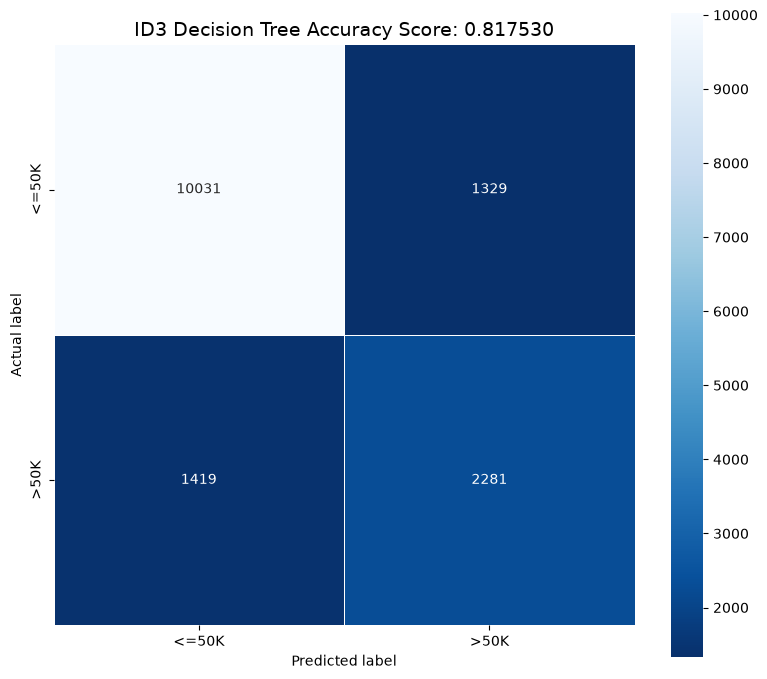

In [8]:
print(f"{STUDENT_NAME} - {MSSV}")

id3_clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
id3_clf.fit(X_train, y_train)

id3_pred = id3_clf.predict(X_test)
id3_score = metrics.accuracy_score(y_test, id3_pred)
id3_report = metrics.classification_report(y_test, id3_pred, output_dict=True)

print("ID3 Accuracy:", id3_score)
print("ID3 Report:\n", metrics.classification_report(y_test, id3_pred))

id3_cm = metrics.confusion_matrix(y_test, id3_pred, labels=id3_clf.classes_)
print("Confusion Matrix (ID3):\n", id3_cm)

plt.figure(figsize=(8, 7))
sns.heatmap(
    id3_cm,
    annot=True,
    fmt="d",
    linewidths=0.5,
    square=True,
    cmap="Blues_r",
    xticklabels=id3_clf.classes_,
    yticklabels=id3_clf.classes_,
)
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title(f"ID3 Decision Tree Accuracy Score: {id3_score:.6f}", size=14)
plt.tight_layout()
plt.show()

Nguyễn Phạm Bảo Khanh - 6451071033
Độ sâu đầy đủ của cây ID3: 51 | Số nút lá: 5327
Trực quan hóa 3 tầng đầu (max_depth=3) của cây ID3 để dễ quan sát các nhánh chính:


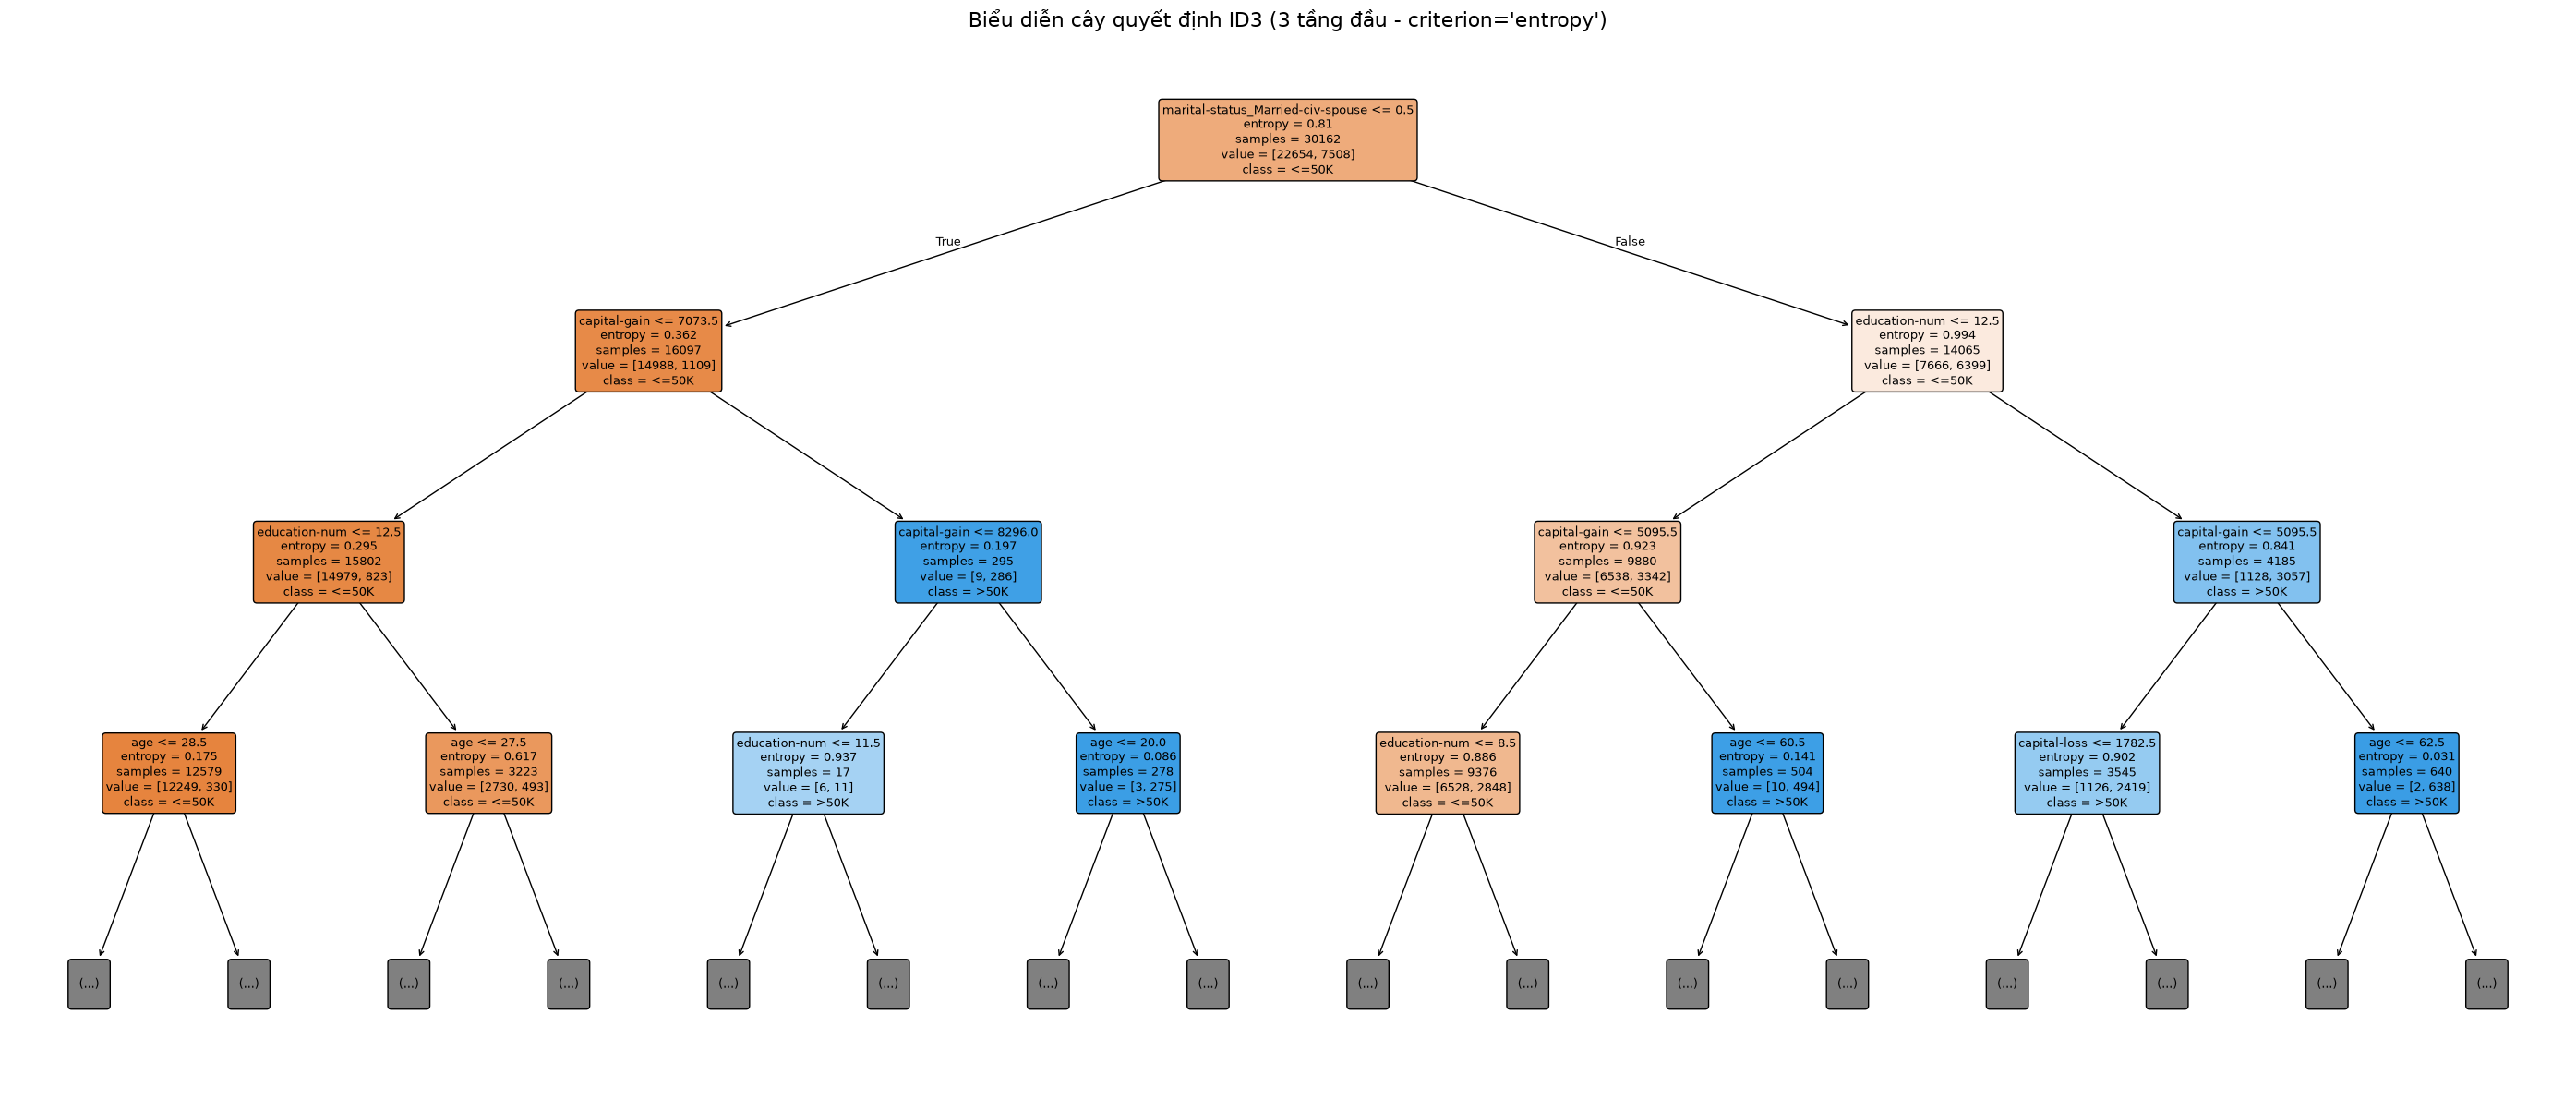

In [9]:
print(f"{STUDENT_NAME} - {MSSV}")
print(f"Độ sâu đầy đủ của cây ID3: {id3_clf.get_depth()} | Số nút lá: {id3_clf.get_n_leaves()}")
print("Trực quan hóa 3 tầng đầu (max_depth=3) của cây ID3 để dễ quan sát các nhánh chính:")

fig, ax = plt.subplots(figsize=(28, 12))
tree.plot_tree(
    id3_clf,
    max_depth=3,
    feature_names=X_train.columns,
    class_names=list(id3_clf.classes_),
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
)
plt.title("Biểu diễn cây quyết định ID3 (3 tầng đầu - criterion='entropy')", fontsize=16)
plt.tight_layout()
plt.show()

**Nhận xét Câu 7:**
- Cây ID3 đạt độ chính xác tổng thể trên tập kiểm thử là **81,75%** (`0.817530`), dự đoán đúng `10.031 / 11.360` mẫu `<=50K` và `2.281 / 3.700` mẫu `>50K`.
- Các nhánh phân chia đầu tiên dựa trên tình trạng hôn nhân (`marital-status_Married-civ-spouse`), thu nhập từ vốn (`capital-gain`) và trình độ học vấn (`education-num`).

## Câu 8: Xây dựng cây quyết định CART (`criterion="gini"`) và đánh giá kết quả

Nguyễn Phạm Bảo Khanh - 6451071033


CART Accuracy: 0.8122841965471448
CART Report:
               precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.62      0.60      0.61      3700

    accuracy                           0.81     15060
   macro avg       0.75      0.74      0.74     15060
weighted avg       0.81      0.81      0.81     15060

Confusion Matrix (CART):
 [[10009  1351]
 [ 1476  2224]]


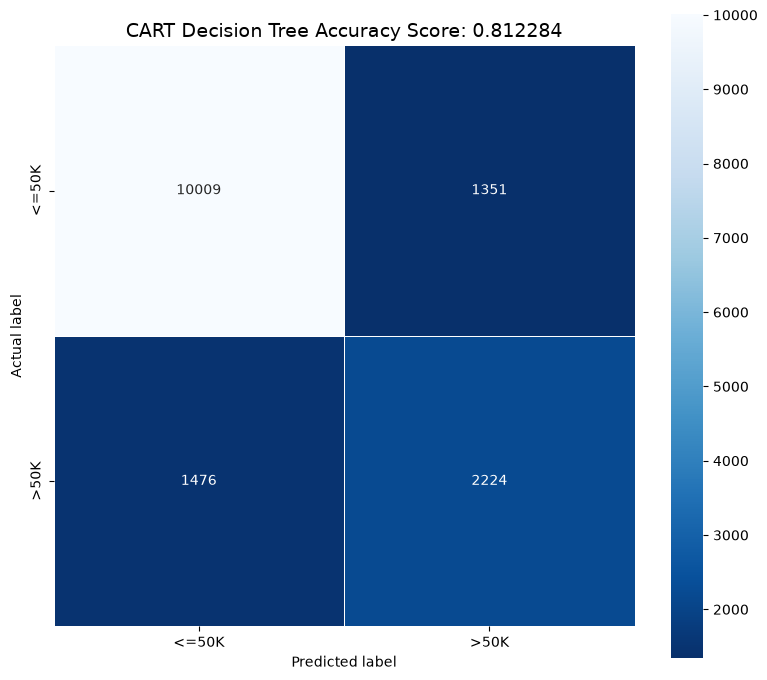

In [10]:
print(f"{STUDENT_NAME} - {MSSV}")

cart_clf = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
cart_clf.fit(X_train, y_train)

cart_pred = cart_clf.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)
cart_report = metrics.classification_report(y_test, cart_pred, output_dict=True)

print("CART Accuracy:", cart_score)
print("CART Report:\n", metrics.classification_report(y_test, cart_pred))

cart_cm = metrics.confusion_matrix(y_test, cart_pred, labels=cart_clf.classes_)
print("Confusion Matrix (CART):\n", cart_cm)

plt.figure(figsize=(8, 7))
sns.heatmap(
    cart_cm,
    annot=True,
    fmt="d",
    linewidths=0.5,
    square=True,
    cmap="Blues_r",
    xticklabels=cart_clf.classes_,
    yticklabels=cart_clf.classes_,
)
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title(f"CART Decision Tree Accuracy Score: {cart_score:.6f}", size=14)
plt.tight_layout()
plt.show()

Nguyễn Phạm Bảo Khanh - 6451071033
Độ sâu đầy đủ của cây CART: 46 | Số nút lá: 5331
Trực quan hóa 3 tầng đầu (max_depth=3) của cây CART để dễ quan sát các nhánh chính:


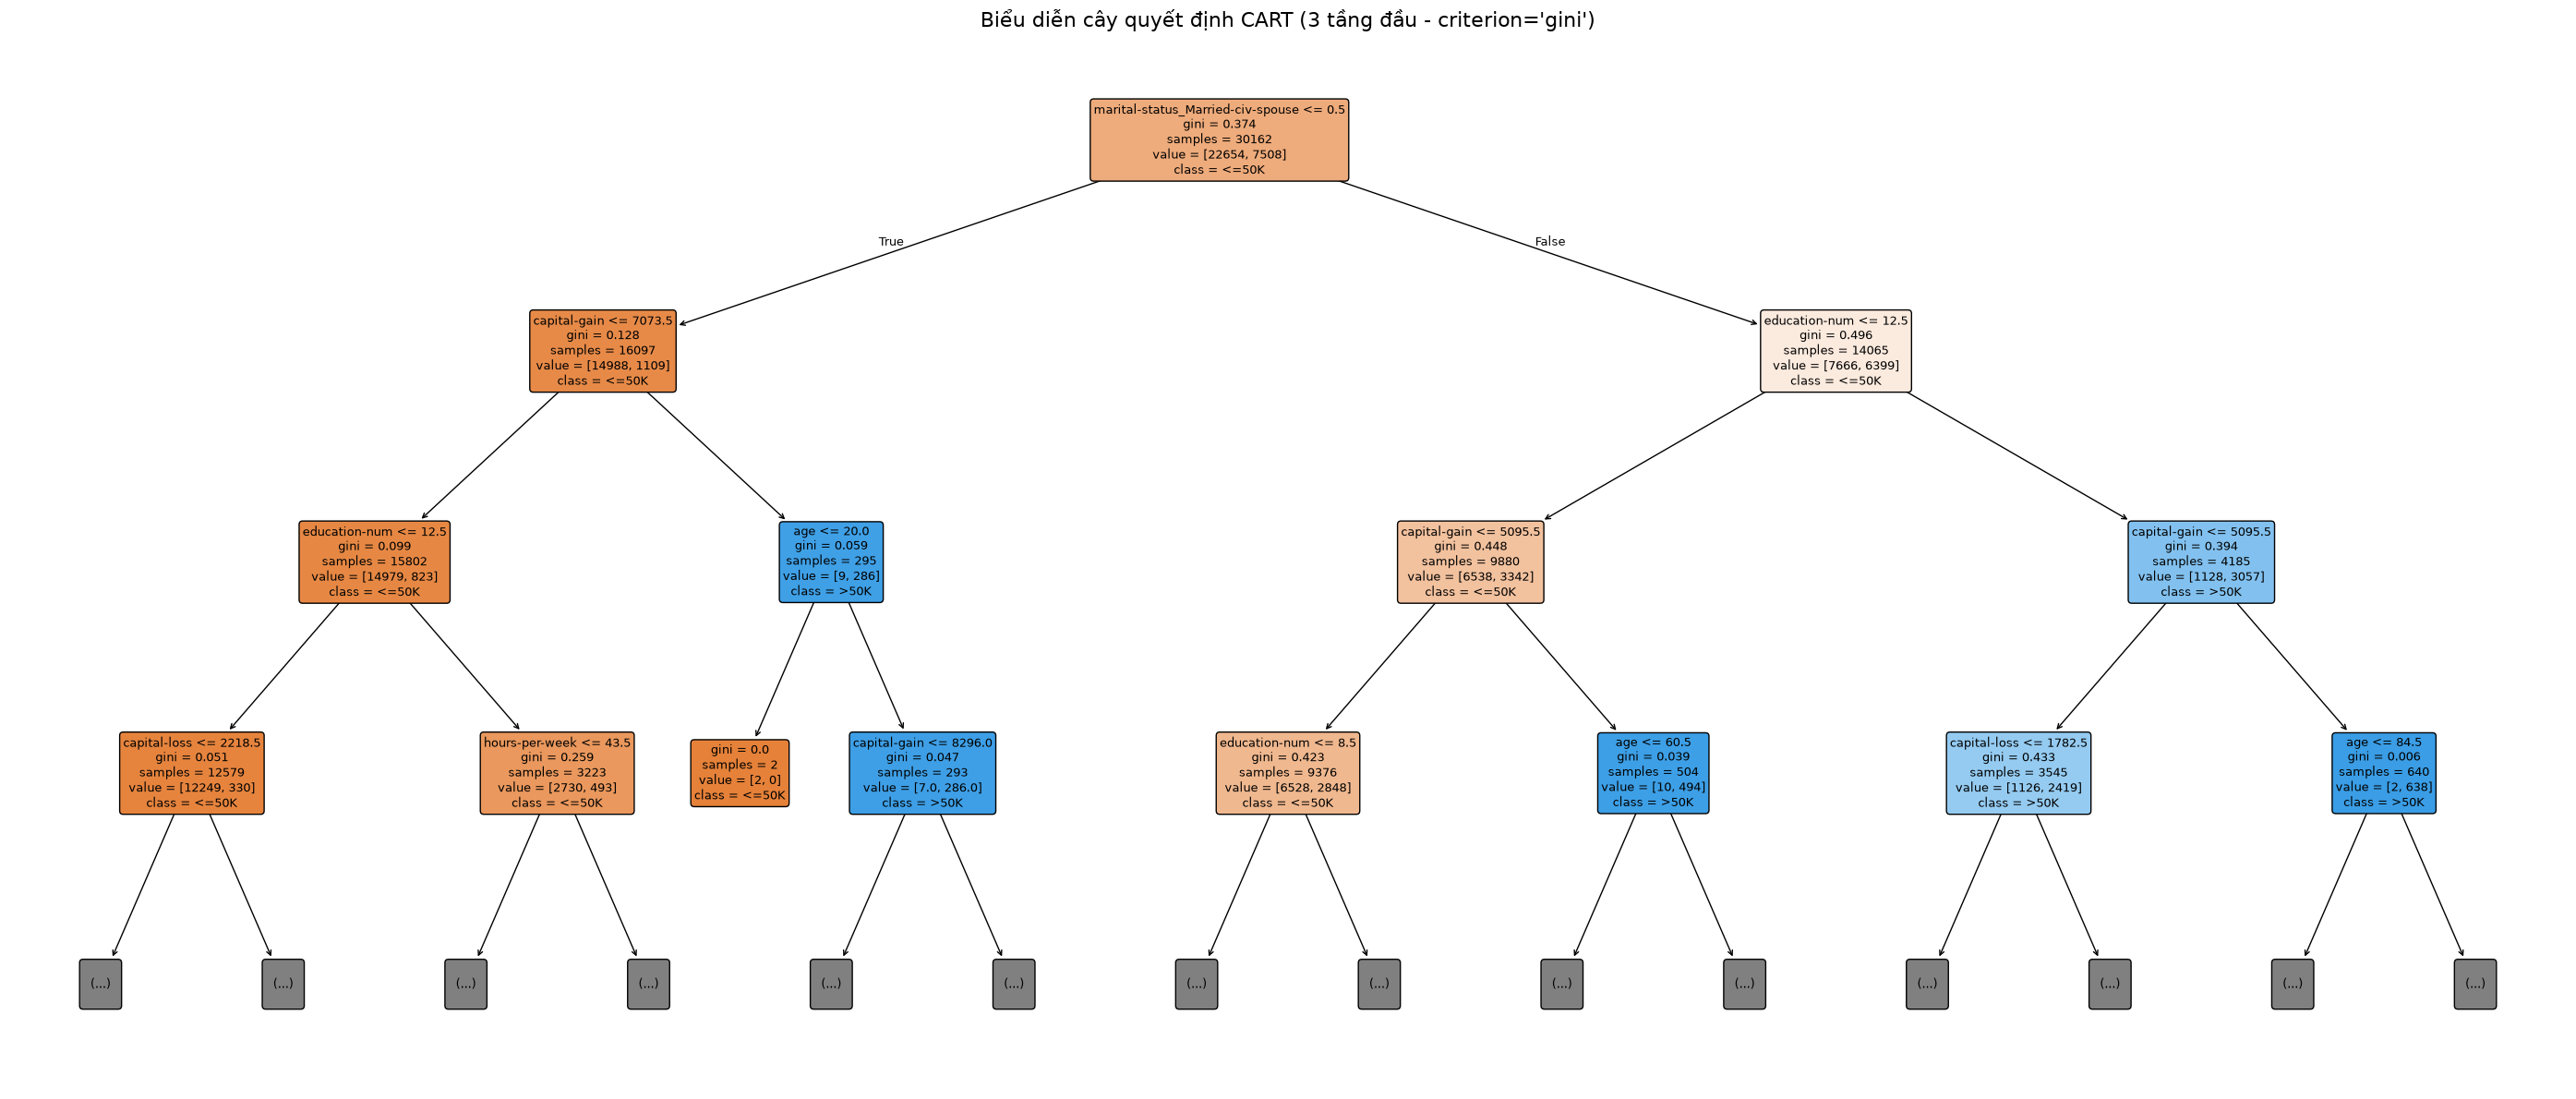

In [11]:
print(f"{STUDENT_NAME} - {MSSV}")
print(f"Độ sâu đầy đủ của cây CART: {cart_clf.get_depth()} | Số nút lá: {cart_clf.get_n_leaves()}")
print("Trực quan hóa 3 tầng đầu (max_depth=3) của cây CART để dễ quan sát các nhánh chính:")

fig, ax = plt.subplots(figsize=(28, 12))
tree.plot_tree(
    cart_clf,
    max_depth=3,
    feature_names=X_train.columns,
    class_names=list(cart_clf.classes_),
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
)
plt.title("Biểu diễn cây quyết định CART (3 tầng đầu - criterion='gini')", fontsize=16)
plt.tight_layout()
plt.show()

**Nhận xét Câu 8:**
- Cây CART (`criterion='gini'`) đạt độ chính xác **81,23%** (`0.812284`), thấp hơn nhẹ so với ID3 (**81,75%**).
- Số mẫu dự đoán đúng là `10.009 / 11.360` cho lớp `<=50K` và `2.224 / 3.700` cho lớp `>50K`.

## Câu 9: Xây dựng mô hình phân lớp Naïve Bayes (`GaussianNB`) và đánh giá kết quả

Nguyễn Phạm Bảo Khanh - 6451071033


Naive Bayes Accuracy: 0.8029216467463479
Naive Bayes Report:
               precision    recall  f1-score   support

       <=50K       0.93      0.80      0.86     11360
        >50K       0.57      0.82      0.67      3700

    accuracy                           0.80     15060
   macro avg       0.75      0.81      0.76     15060
weighted avg       0.84      0.80      0.81     15060

Confusion Matrix (Naive Bayes):
 [[9073 2287]
 [ 681 3019]]


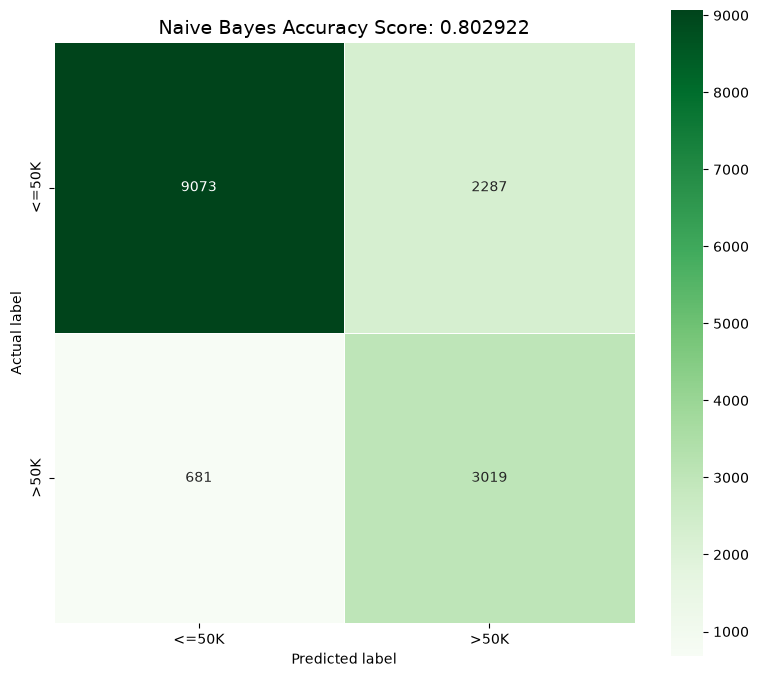

In [12]:
print(f"{STUDENT_NAME} - {MSSV}")

gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
bayes_report = metrics.classification_report(y_test, bayes_pred, output_dict=True)

print("Naive Bayes Accuracy:", bayes_score)
print("Naive Bayes Report:\n", metrics.classification_report(y_test, bayes_pred))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred, labels=gnb.classes_)
print("Confusion Matrix (Naive Bayes):\n", bayes_cm)

plt.figure(figsize=(8, 7))
sns.heatmap(
    bayes_cm,
    annot=True,
    fmt="d",
    linewidths=0.5,
    square=True,
    cmap="Greens",
    xticklabels=gnb.classes_,
    yticklabels=gnb.classes_,
)
plt.ylabel("Actual label")
plt.xlabel("Predicted label")
plt.title(f"Naive Bayes Accuracy Score: {bayes_score:.6f}", size=14)
plt.tight_layout()
plt.show()

**Nhận xét Câu 9:**
- Mô hình `GaussianNB` đạt độ chính xác tổng thể **80,29%** (`0.802922`).
- Dù có số dự đoán nhầm từ `<=50K` sang `>50K` nhiều hơn (`2.287` mẫu, khiến Precision lớp `>50K` giảm còn `0.57`), mô hình lại đạt Recall cho lớp `>50K` rất cao (**0.82**, nhận diện đúng `3.019 / 3.700` người có thu nhập trên 50K).

## Câu 10: So sánh kết quả của các mô hình

Nguyễn Phạm Bảo Khanh - 6451071033


,Mô hình,Accuracy,Precision (<=50K),Recall (<=50K),F1 (<=50K),Precision (>50K),Recall (>50K),F1 (>50K),Macro Avg F1,Weighted Avg F1
0,ID3 (Entropy),0.8175,0.8761,0.8830,0.8795,0.6319,0.6165,0.6241,0.7518,0.8168
1,CART (Gini),0.8123,0.8715,0.8811,0.8763,0.6221,0.6011,0.6114,0.7438,0.8112
2,Naïve Bayes (GaussianNB),0.8029,0.9302,0.7987,0.8594,0.5690,0.8159,0.6704,0.7649,0.8130


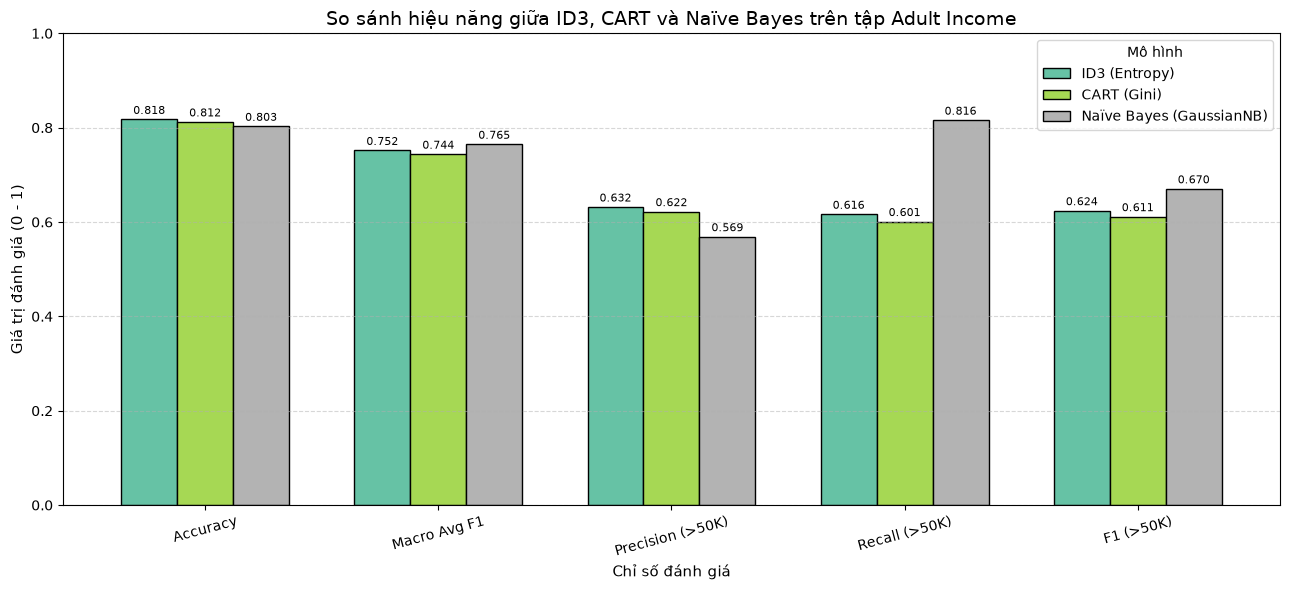

In [13]:
print(f"{STUDENT_NAME} - {MSSV}")

models_info = [
    ("ID3 (Entropy)", id3_score, id3_report),
    ("CART (Gini)", cart_score, cart_report),
    ("Naïve Bayes (GaussianNB)", bayes_score, bayes_report),
]

comparison_rows = []
for model_name, acc, rep in models_info:
    comparison_rows.append({
        "Mô hình": model_name,
        "Accuracy": acc,
        "Precision (<=50K)": rep["<=50K"]["precision"],
        "Recall (<=50K)": rep["<=50K"]["recall"],
        "F1 (<=50K)": rep["<=50K"]["f1-score"],
        "Precision (>50K)": rep[">50K"]["precision"],
        "Recall (>50K)": rep[">50K"]["recall"],
        "F1 (>50K)": rep[">50K"]["f1-score"],
        "Macro Avg F1": rep["macro avg"]["f1-score"],
        "Weighted Avg F1": rep["weighted avg"]["f1-score"],
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(4))

metric_cols = ["Accuracy", "Macro Avg F1", "Precision (>50K)", "Recall (>50K)", "F1 (>50K)"]
plot_df = comparison_df.set_index("Mô hình")[metric_cols]

ax = plot_df.T.plot(kind="bar", figsize=(13, 6), width=0.72, colormap="Set2", edgecolor="black")
plt.title("So sánh hiệu năng giữa ID3, CART và Naïve Bayes trên tập Adult Income", fontsize=14)
plt.ylabel("Giá trị đánh giá (0 - 1)", fontsize=11)
plt.xlabel("Chỉ số đánh giá", fontsize=11)
plt.ylim(0, 1.0)
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(title="Mô hình", loc="upper right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=8)

plt.tight_layout()
plt.show()

**Nhận xét và so sánh tổng hợp (Câu 10):**
1. **Về độ chính xác tổng thể (Accuracy):**
   - **ID3 (Entropy)** đạt kết quả cao nhất với **81,75%** (`0.8175`), nhỉnh hơn **CART (Gini)** đạt **81,23%** (`0.8123`), và cao hơn **Naïve Bayes (GaussianNB)** đạt **80,29%** (`0.8029`).
2. **Về sự cân bằng giữa hai lớp (`<=50K` và `>50K`):**
   - Hai mô hình cây quyết định (**ID3** và **CART**) xử lý tốt dữ liệu sau khi mã hóa one-hot (103 đặc trưng) nhờ khả năng tự động nắm bắt tương tác phi tuyến giữa các thuộc tính (như tình trạng hôn nhân, số năm học vấn, thu nhập từ vốn) mà không cần giả định độc lập hay phân phối chuẩn.
   - **GaussianNB** giả định các đặc trưng độc lập có điều kiện và tuân theo phân phối chuẩn, vốn không hoàn toàn phù hợp với các cột nhị phân one-hot thưa và các cột số lệch phân phối như `capital-gain`, `capital-loss`. Hệ quả là GaussianNB dự đoán nhầm nhiều mẫu `<=50K` thành `>50K` (2.287 trường hợp, Precision `>50K` = `0.57`), làm giảm độ chính xác tổng thể.
   - Ngược lại, **GaussianNB** lại đạt **Recall lớp `>50K` cao nhất (0.82)** và **F1 lớp `>50K` cao nhất (0.67)** (Macro Avg F1 = `0.76` so với `0.75` của ID3 và `0.74` của CART), giúp bỏ sót rất ít người có thu nhập cao.
3. **Kết luận lựa chọn mô hình:**
   - Nếu mục tiêu ưu tiên độ chính xác tổng thể và hạn chế báo nhầm lớp `>50K`, **ID3** là lựa chọn tốt nhất trong ba mô hình (và có thể cắt tỉa `max_depth`/`min_samples_leaf` để tránh cây quá sâu như `depth=51`).
   - Nếu bài toán ưu tiên phát hiện tối đa nhóm đối tượng thu nhập `>50K` (tối đa hóa Recall lớp dương), **Naïve Bayes** tỏ ra hiệu quả hơn.